In [8]:
import requests
import pandas as pd

USERNAME = "rovaimt"
CSV_FILE = "bt_log202505.csv"
BASE_URL = "https://apps.clarksonmsda.org/traffic-api"

In [9]:
r = requests.get(f"{BASE_URL}/cams", params={"username": USERNAME})
print(r.status_code)
print(r.json())

200
{'cams': ['109_high', '109_low'], 'code': 1, 'msg': 'ok'}


In [10]:
df = pd.read_csv(CSV_FILE, parse_dates=["dts"])
print(len(df), "rows")
print(df["mac"].nunique(), "different MACs")
df.head()

136711 rows
120897 different MACs


,dts,mac,is_new
0,2025-05-01 00:12:29.308,47:30:49:6c:6b:88,True
1,2025-05-01 00:22:00.534,45:2d:1a:ac:4d:ef,True
2,2025-05-01 00:30:46.988,53:d6:ac:bb:d1:42,True
3,2025-05-01 00:30:47.337,e4:7f:6a:81:03:79,True
4,2025-05-01 00:40:35.224,48:5b:a4:7b:ea:dc,True


In [13]:
df["dts"] = pd.to_datetime(df["dts"], format="mixed", errors="coerce")
print(df["dts"].isna().sum(), "rows with bad dates removed")
df = df.dropna(subset=["dts"])
df["day"] = df["dts"].dt.date
df["hour"] = df["dts"].dt.hour

counts = (df.groupby("mac")
            .agg(days=("day", "nunique"),
                 sightings=("dts", "size"),
                 usual_hour=("hour", "median"))
            .sort_values(["days", "sightings"], ascending=False))

top10 = counts.head(10)
top10

0 rows with bad dates removed


,days,sightings,usual_hour
mac,,,
a0:0b:16:04:85:16,28,141,11.0
80:c4:1b:7b:6a:ff,27,67,12.0
d4:ad:fc:20:f1:40,25,50,7.0
d0:2e:ab:ef:b8:dd,23,51,14.0
a0:76:4e:f3:2a:39,21,37,8.0
df:ed:79:f3:7b:b0,20,36,12.0
40:79:12:87:52:0a,20,33,10.0
a2:07:00:05:38:86,19,26,16.0
ef:70:09:a5:3b:ae,18,63,15.0


In [ ]:
mac = top10.index[0]                              
rows = df[df["mac"] == mac]
dt = rows["dts"].iloc[0]                          
dt_str = dt.strftime("%Y-%m-%dT%H:%M:%S")         
print("MAC:", mac, " Bluetooth time:", dt_str)

for cam in ["109_high", "109_low"]:
    r = requests.get(f"{BASE_URL}/logs",
                     params={"username": USERNAME, "cam": cam, "datetime": dt_str})
    print(cam, r.status_code, r.json())

MAC: a0:0b:16:04:85:16  Bluetooth time: 2025-05-01T08:18:16
109_high 200 {'cam': '109_high', 'code': 1, 'delta_seconds': 0.2, 'matched_datetime': '2025-05-01 08:18:15.800000', 'msg': 'ok', 'record': {'box': [131.467, 143.222, 125.6997, 88.828], 'cam': '109_high', 'cls': 2, 'cross': [[131, 143], [141, 139]], 'debug_img': 'traffic_data/img/debug/2025-05-01_h/081815_20927.jpg', 'dto': '2025-05-01 08:18:15.800000', 'frame_dto': '2025-05-01 08:18:15', 'full_img': 'traffic_data/img/full/2025-05-01_h/081815_20927.jpg', 'intersection': [132, 142], 'point_len': 107, 'probs': 0.94, 'save_dto': '2025-05-01 08:18:18.377814', 'seq_len': 10, 'snd': {'diff': 0.10125899314880371, 'now': 1746101903.48434, 'res': {'dba': [86.6, 85.08, 84.02, 82.5, 81.15, 79.96, 77.68, 77.67, 76.4, 79.18, 81.51, 82.76, 80.76, 79.96, 81.26, 78.89, 77.41, 77.68, 78.96, 81.52, 82.77], 'kd': 5000, 'ke': 1746101898750, 'ks': 1746101893750}, 'snd': 'traffic_data/snd/2025-05-01_h/081815_800000_.mp3', 'snd_lvl': 55.7181324110671

200 image/jpeg


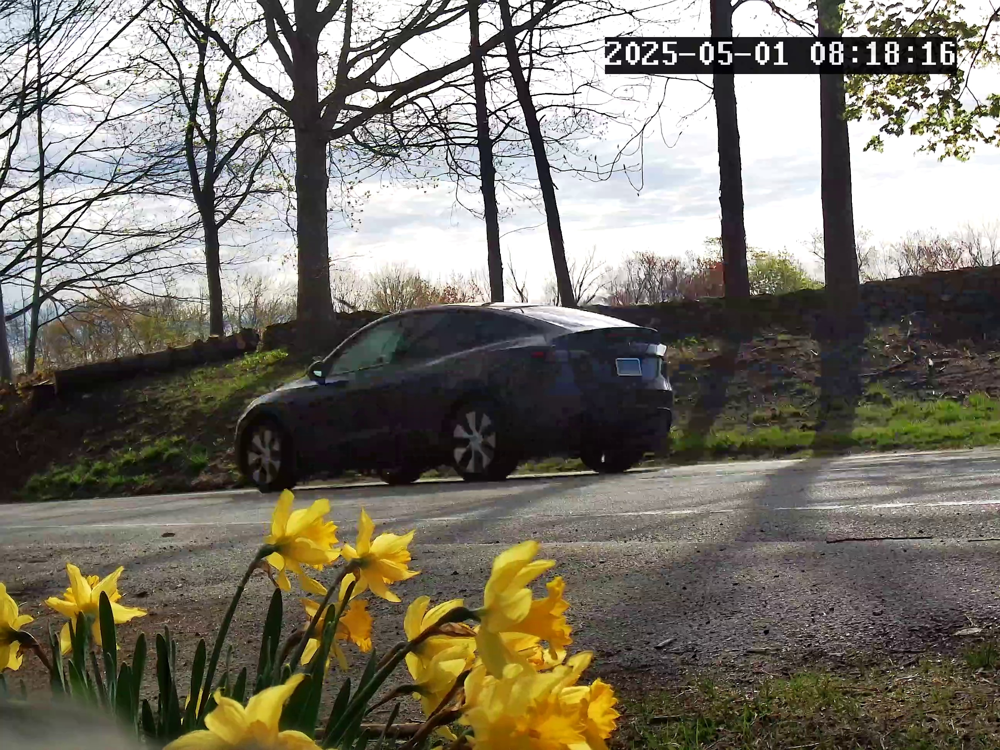

In [15]:
from IPython.display import Image, display

r = requests.get(f"{BASE_URL}/images",
                 params={"username": USERNAME, "cam": "109_low",
                         "datetime": dt_str, "type": "full"})
print(r.status_code, r.headers.get("Content-Type"))

with open("test.jpg", "wb") as f:
    f.write(r.content)

display(Image("test.jpg", width=700))

In [16]:
import os

def best_match(dt_str):
    """Ask both cameras and return the one with the smallest delta_seconds."""
    best = None
    for cam in ["109_high", "109_low"]:
        r = requests.get(f"{BASE_URL}/logs",
                         params={"username": USERNAME, "cam": cam, "datetime": dt_str})
        if r.status_code != 200:
            continue
        rec = r.json()
        if best is None or abs(rec["delta_seconds"]) < abs(best["delta_seconds"]):
            best = rec
    return best

results = []
for rank, mac in enumerate(top10.index, start=1):
    rows = df[df["mac"] == mac].drop_duplicates("day")        # one sighting per day
    picks = rows.sample(min(4, len(rows)), random_state=1)["dts"].sort_values()

    folder = f"images/{rank:02d}_{mac.replace(':', '')}"
    os.makedirs(folder, exist_ok=True)

    for dt in picks:
        dt_str = dt.strftime("%Y-%m-%dT%H:%M:%S")
        rec = best_match(dt_str)
        if rec is None:
            print(mac, dt_str, "no match")
            continue
        img = requests.get(f"{BASE_URL}/images",
                           params={"username": USERNAME, "cam": rec["cam"],
                                   "datetime": dt_str, "type": "full"})
        path = f"{folder}/{dt:%Y%m%d_%H%M%S}.jpg"
        with open(path, "wb") as f:
            f.write(img.content)
        results.append({"rank": rank, "mac": mac, "bt_time": dt_str,
                        "cam": rec["cam"], "delta_seconds": rec["delta_seconds"],
                        "image": path})
    print(f"#{rank} {mac}: done")

res = pd.DataFrame(results)
res

#1 a0:0b:16:04:85:16: done
#2 80:c4:1b:7b:6a:ff: done
#3 d4:ad:fc:20:f1:40: done
#4 d0:2e:ab:ef:b8:dd: done
#5 a0:76:4e:f3:2a:39: done
#6 df:ed:79:f3:7b:b0: done
#7 40:79:12:87:52:0a: done
#8 a2:07:00:05:38:86: done
#9 ef:70:09:a5:3b:ae: done
#10 dd:45:a9:90:84:41: done


,rank,mac,bt_time,cam,delta_seconds,image
0,1,a0:0b:16:04:85:16,2025-05-20T07:37:06,109_high,1.130,images/01_a00b16048516/20250520_073706.jpg
1,1,a0:0b:16:04:85:16,2025-05-22T07:36:59,109_high,14.000,images/01_a00b16048516/20250522_073659.jpg
2,1,a0:0b:16:04:85:16,2025-05-23T07:38:48,109_high,0.400,images/01_a00b16048516/20250523_073848.jpg
3,1,a0:0b:16:04:85:16,2025-05-27T07:42:30,109_high,6.503,images/01_a00b16048516/20250527_074230.jpg
4,2,80:c4:1b:7b:6a:ff,2025-05-05T09:44:49,109_high,0.500,images/02_80c41b7b6aff/20250505_094449.jpg
5,2,80:c4:1b:7b:6a:ff,2025-05-17T11:31:27,109_high,13.300,images/02_80c41b7b6aff/20250517_113127.jpg
6,2,80:c4:1b:7b:6a:ff,2025-05-20T17:09:02,109_high,4.228,images/02_80c41b7b6aff/20250520_170902.jpg
7,2,80:c4:1b:7b:6a:ff,2025-05-22T14:37:07,109_high,19.730,images/02_80c41b7b6aff/20250522_143707.jpg
8,3,d4:ad:fc:20:f1:40,2025-05-05T07:05:01,109_low,0.400,images/03_d4adfc20f140/20250505_070501.jpg
9,3,d4:ad:fc:20:f1:40,2025-05-17T07:01:30,109_high,29.400,images/03_d4adfc20f140/20250517_070130.jpg


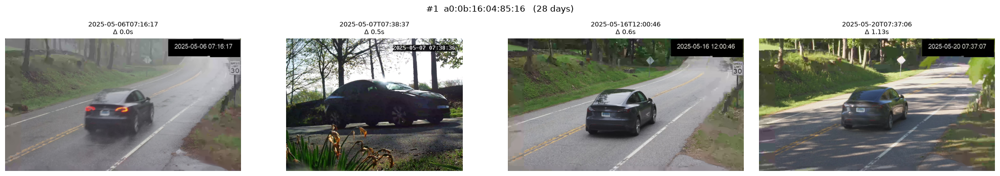

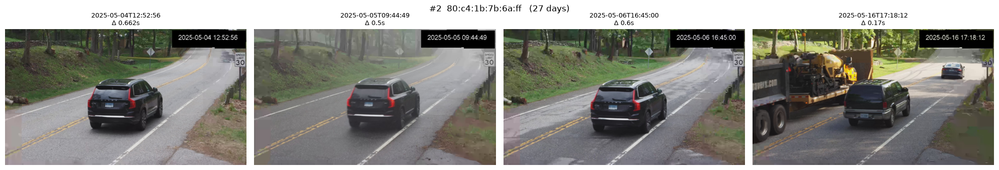

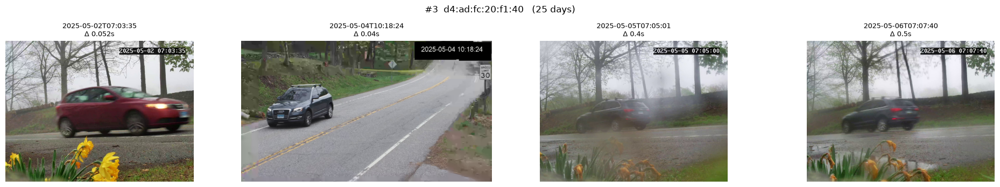

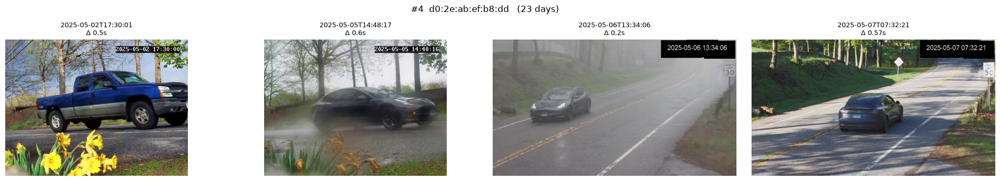

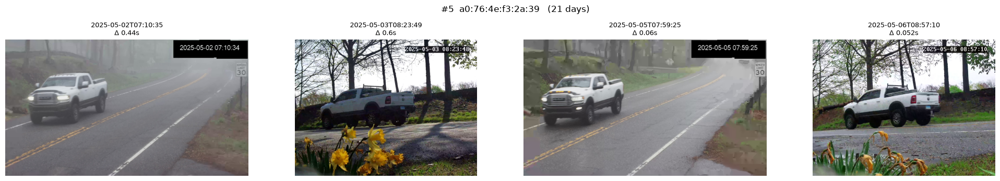

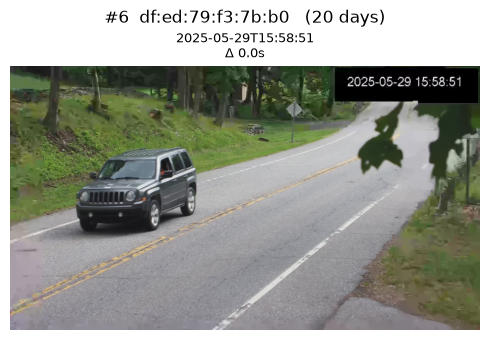

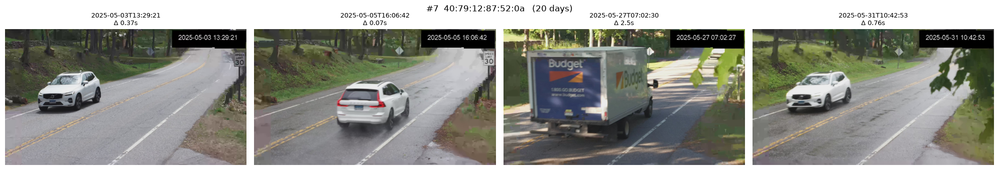

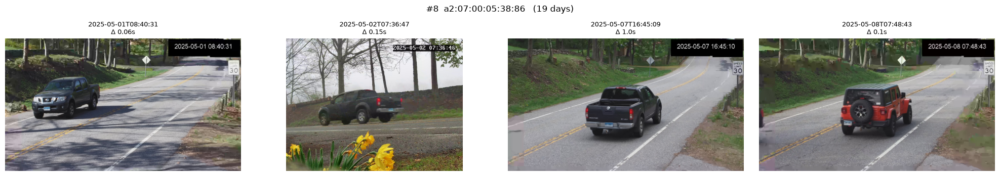

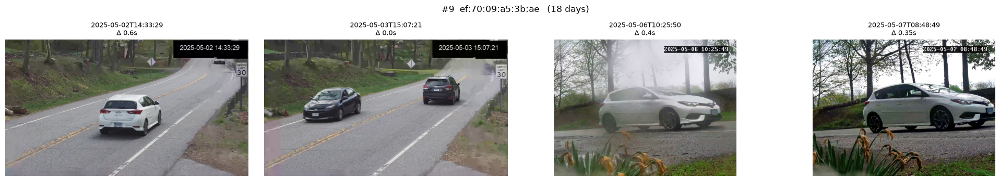

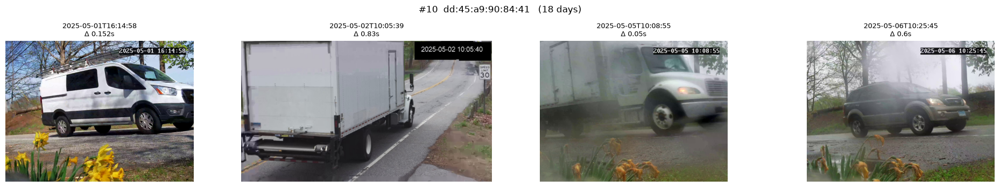

In [22]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

for rank, mac in enumerate(top10.index, start=1):
    group = res[res["mac"] == mac]
    fig, axes = plt.subplots(1, len(group), figsize=(5 * len(group), 3.5))
    if len(group) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, group.iterrows()):
        ax.imshow(mpimg.imread(row["image"]))
        ax.set_title(f'{row["bt_time"]}\nΔ {row["delta_seconds"]}s', fontsize=9)
        ax.axis("off")
    fig.suptitle(f'#{rank}  {mac}   ({top10.loc[mac, "days"]} days)', fontsize=12)
    plt.tight_layout()
    plt.show()

In [ ]:
import shutil
shutil.rmtree("images", ignore_errors=True)    

results = []
for rank, mac in enumerate(top10.index, start=1):
    rows = df[df["mac"] == mac].drop_duplicates("day")
    candidates = rows.sample(min(15, len(rows)), random_state=1)["dts"].sort_values()

    folder = f"images/{rank:02d}_{mac.replace(':', '')}"
    os.makedirs(folder, exist_ok=True)
    kept = 0
    for dt in candidates:
        if kept == 4:
            break
        dt_str = dt.strftime("%Y-%m-%dT%H:%M:%S")
        rec = best_match(dt_str)
        if rec is None or abs(rec["delta_seconds"]) > 3:
            continue                           
        img = requests.get(f"{BASE_URL}/images",
                           params={"username": USERNAME, "cam": rec["cam"],
                                   "datetime": dt_str, "type": "full"})
        path = f"{folder}/{dt:%Y%m%d_%H%M%S}.jpg"
        with open(path, "wb") as f:
            f.write(img.content)
        results.append({"rank": rank, "mac": mac, "bt_time": dt_str,
                        "cam": rec["cam"], "delta_seconds": rec["delta_seconds"],
                        "image": path})
        kept += 1
    print(f"#{rank} {mac}: kept {kept} photos")

res = pd.DataFrame(results)

#1 a0:0b:16:04:85:16: kept 4 photos
#2 80:c4:1b:7b:6a:ff: kept 4 photos
#3 d4:ad:fc:20:f1:40: kept 4 photos
#4 d0:2e:ab:ef:b8:dd: kept 4 photos
#5 a0:76:4e:f3:2a:39: kept 4 photos
#6 df:ed:79:f3:7b:b0: kept 1 photos
#7 40:79:12:87:52:0a: kept 4 photos
#8 a2:07:00:05:38:86: kept 4 photos
#9 ef:70:09:a5:3b:ae: kept 4 photos
#10 dd:45:a9:90:84:41: kept 4 photos


In [ ]:
mac = top10.index[5]          
rows = df[df["mac"] == mac].drop_duplicates("day")
folder = f"images/06_{mac.replace(':', '')}"
kept = len(res[res["mac"] == mac])

for dt in rows["dts"].sort_values():
    if kept == 4:
        break
    dt_str = dt.strftime("%Y-%m-%dT%H:%M:%S")
    if dt_str in res["bt_time"].values:
        continue
    rec = best_match(dt_str)
    if rec is None or abs(rec["delta_seconds"]) > 3:
        continue
    img = requests.get(f"{BASE_URL}/images",
                       params={"username": USERNAME, "cam": rec["cam"],
                               "datetime": dt_str, "type": "full"})
    path = f"{folder}/{dt:%Y%m%d_%H%M%S}.jpg"
    with open(path, "wb") as f:
        f.write(img.content)
    res.loc[len(res)] = {"rank": 6, "mac": mac, "bt_time": dt_str, "cam": rec["cam"],
                         "delta_seconds": rec["delta_seconds"], "image": path}
    kept += 1
print("kept", kept, "photos for #6")

kept 1 photos for #6


In [23]:
mac = top10.index[5]
rows = df[df["mac"] == mac].drop_duplicates("day")

checks = []
for dt in rows["dts"].sort_values():
    dt_str = dt.strftime("%Y-%m-%dT%H:%M:%S")
    rec = best_match(dt_str)
    checks.append({"bt_time": dt_str,
                   "cam": rec["cam"] if rec else None,
                   "delta_seconds": rec["delta_seconds"] if rec else None})

pd.DataFrame(checks)

,bt_time,cam,delta_seconds
0,2025-05-01T06:37:49,109_low,1353.000
1,2025-05-02T06:46:12,109_low,836.100
2,2025-05-05T06:47:06,109_low,789.150
3,2025-05-06T06:40:54,109_high,1152.300
4,2025-05-07T06:22:02,109_high,2296.200
5,2025-05-08T06:34:35,109_high,1720.900
6,2025-05-09T06:47:58,109_high,727.300
7,2025-05-11T13:52:37,109_high,4.500
8,2025-05-12T06:37:11,109_high,1446.040
9,2025-05-13T06:19:09,109_high,2454.300


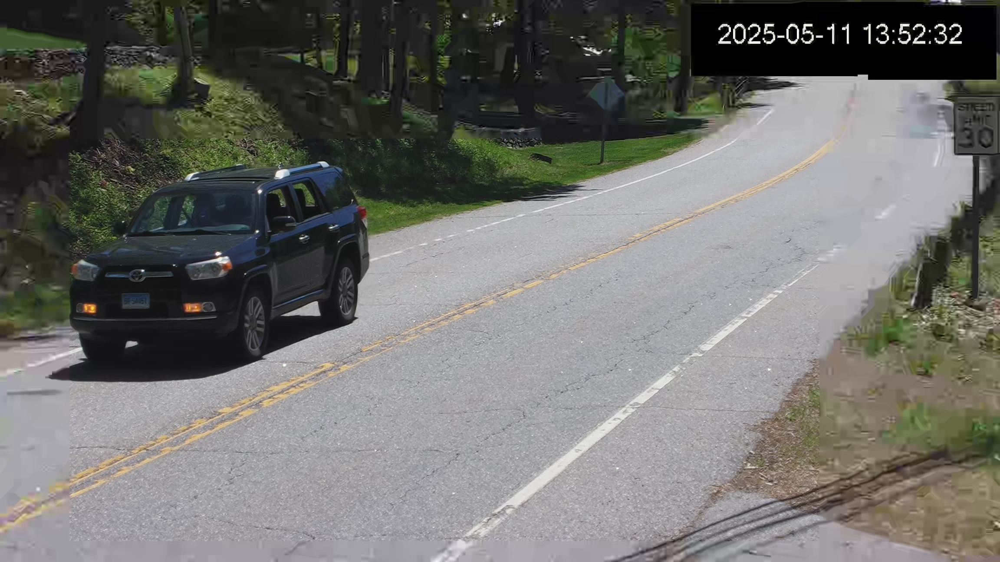

In [24]:
dt_str = "2025-05-11T13:52:37"
rec = best_match(dt_str)
img = requests.get(f"{BASE_URL}/images",
                   params={"username": USERNAME, "cam": rec["cam"],
                           "datetime": dt_str, "type": "full"})
path = f"images/06_{top10.index[5].replace(':', '')}/20250511_135237.jpg"
with open(path, "wb") as f:
    f.write(img.content)
res.loc[len(res)] = {"rank": 6, "mac": top10.index[5], "bt_time": dt_str, "cam": rec["cam"],
                     "delta_seconds": rec["delta_seconds"], "image": path}

display(Image(path, width=600))

In [25]:
verdict = {
    top10.index[0]: "✅ Same vehicle: dark gray Tesla Model Y (4/4 photos). Mostly ~7:15-7:40 am.",
    top10.index[1]: "✅ Likely same: black Volvo XC90 (3/4 photos). Mismatch photo shows a dark SUV behind a dump truck.",
    top10.index[2]: "⚠️ Probably a dark SUV around 7:05 am (2-3/4 photos); one photo is a red sedan.",
    top10.index[3]: "✅ Likely same: dark Tesla Model Y (3/4 photos). Note #1 is also a dark Model Y - on May 7 both passed 6 minutes apart.",
    top10.index[4]: "✅ Same vehicle: white Ram pickup (4/4 photos). Mornings 7-9 am.",
    top10.index[5]: "❓ Unconfirmed: usually seen ~6:20-6:50 am when the camera recorded no vehicles (nearest detection 10-40 min away). The 2 close matches show different vehicles (gray Jeep Patriot, blue Toyota 4Runner).",
    top10.index[6]: "✅ Likely same: white Volvo XC60 (3/4 photos). Mismatch is a Budget truck (delta 2.5 s).",
    top10.index[7]: "✅ Likely same: dark pickup (3/4 photos). Mismatch is a red Jeep Wrangler.",
    top10.index[8]: "✅ Likely same: white Toyota Corolla hatchback (3/4 photos).",
    top10.index[9]: "⚠️ Possibly a delivery vehicle: white box truck at ~10:05 am on two days; other photos show a white van and a dark SUV.",
}

In [26]:
lines = [
    "# Traffic API Lab: 10 Most Common Vehicles by Bluetooth MAC",
    "",
    f"**Data:** `{CSV_FILE}` (May 2025): {len(df):,} Bluetooth sightings, {df['mac'].nunique():,} different MACs.",
    "",
    "## Method",
    "1. Loaded the CSV and grouped sightings by MAC address.",
    "2. Ranked MACs by **number of different days seen** (not raw sightings), so a device parked near the sensor for one day doesn't rank high, and rotating phone addresses drop out because they never repeat.",
    "3. For each top MAC, called `/logs` on both cameras (`109_high`, `109_low`) and kept the one with the smallest `delta_seconds`.",
    "4. Kept only matches with `delta_seconds` ≤ 3 s, since larger gaps often showed a different car. Downloaded up to 4 photos per MAC from different days with `/images`.",
    "5. Compared the photos by eye.",
    "",
    "## Results",
    "",
    "| Rank | MAC | Days seen | Sightings | Usual hour | Verdict |",
    "|---|---|---|---|---|---|",
]
for i, (mac, row) in enumerate(top10.iterrows(), start=1):
    lines.append(f"| {i} | `{mac}` | {row['days']} | {row['sightings']} | {int(row['usual_hour'])}:00 | {verdict[mac]} |")

lines += ["", "## Observations",
          "- Most confirmed vehicles are Teslas and Volvos, which use the owner's phone as a Bluetooth key, so they likely broadcast a fixed address constantly.",
          "- About 1 in 4 photos showed a different vehicle even when the delta was small, because the sensor can hear a car while another one is in front of the camera.",
          "- #6 shows the camera seems to record no vehicles before about 7 am, so early commuters are hard to confirm.",
          "- #1 and #4 are both dark Tesla Model Ys with different MACs: either two similar cars or one car with two Bluetooth radios.",
          "", "## Photos", ""]

for i, mac in enumerate(top10.index, start=1):
    lines += [f"### #{i} `{mac}`", "", verdict[mac], ""]
    for _, r in res[res["mac"] == mac].iterrows():
        lines.append(f'<img src="{r["image"]}" width="300" title="{r["bt_time"]} (delta {r["delta_seconds"]} s)">')
    lines.append("")

with open("README.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))
print("README.md written")

README.md written
